# Process Mining assignment: Sepsis Cases event log (pm4py)

Process: **sepsis patient treatment in a hospital** (Sepsis Cases - Event Log, 4TU).
The notebook follows the structure of `esercitazione_pm4py` and covers points 1, 2, 4, 5, 6 and 7 of the assignment
(point 3, the hand drawings, and point 8, the slides, are done separately).

In [ ]:
!pip -q install pm4py
!apt-get -qq install graphviz > /dev/null 2>&1

In [ ]:
import os, random, json
from copy import deepcopy
import numpy as np
import pandas as pd
import pm4py
from pm4py import PetriNet, Marking
from pm4py.objects.petri_net.utils import petri_utils
from pm4py.objects.log.obj import EventLog, Trace
from pm4py.algo.evaluation.generalization import algorithm as generalization_evaluator
from pm4py.algo.evaluation.simplicity import algorithm as simplicity_evaluator
from pm4py.conformance import fitness_alignments, precision_alignments

random.seed(42)
pd.set_option("display.max_colwidth", 120)



  Welcome to PM4Py — Community Version
  Open-Source License (AGPL v3)

  📚 Docs & Examples:
     https://processintelligence.solutions/pm4py

  ⚖️  License: AGPL v3 — Commercial use requires open-sourcing your application.
     Business use without open-sourcing? A commercial license is available:
     https://processintelligence.solutions/pm4py#licensing




## 1. Event log

**Upload and import the original log** (if you are not on Colab, put the file next to the notebook).

In [ ]:
FILE = "Sepsis Cases - Event Log.xes"

full_log = pm4py.read_xes(FILE, return_legacy_log_object=True)   # EventLog object, like in the class notebook
print("Traces in the original log:", len(full_log))
print("Variants in the original log:", len(pm4py.get_variants(full_log)))

/home/ahmed/Desktop/process_mining/.venv/lib/python3.12/site-packages/pm4py/utils.py:1027: UserWarning: Install the optional requirement `r4pm` to import/export files faster. `rustxes` remains supported as a fallback.
  warnings.warn(


/home/ahmed/Desktop/process_mining/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm



parsing log, completed traces ::   0%|          | 0/1050 [00:00<?, ?it/s]


parsing log, completed traces ::  13%|█▎        | 137/1050 [00:00<00:00, 1368.28it/s]


parsing log, completed traces ::  28%|██▊       | 292/1050 [00:00<00:00, 1460.44it/s]


parsing log, completed traces ::  42%|████▏     | 438/1050 [00:00<00:00, 1439.60it/s]


parsing log, completed traces ::  56%|█████▌    | 586/1050 [00:00<00:00, 1454.71it/s]


parsing log, completed traces ::  70%|███████   | 737/1050 [00:00<00:00, 1466.98it/s]


parsing log, completed traces ::  86%|████████▌ | 902/1050 [00:00<00:00, 1520.38it/s]


parsing log, completed traces :: 100%|██████████| 1050/1050 [00:00<00:00, 1508.11it/s]

Traces in the original log: 1050
Variants in the original log: 846


The original log has about 1050 traces but more than 800 variants, and most of them occur only once.
Models mined from it would be very noisy, and alignments would be slow.
We therefore **build our own event log** from the Sepsis process by keeping the `K` most frequent variants.
Requirements: at least 20 variants, at least 100 traces, and non-uniform variant frequencies.

In [ ]:
K = 25   # number of variants kept (>= 20)

log = pm4py.filter_variants_top_k(full_log, K)

variants = pm4py.get_variants(log)
var_counts = {v: len(t) if not isinstance(t, int) else t for v, t in variants.items()}
freqs = sorted(var_counts.values(), reverse=True)

print("Traces :", len(log))
print("Variants:", len(variants))
print("Variant frequencies:", freqs)

assert len(variants) >= 20,        "need at least 20 variants"
assert len(log) >= 100,            "need at least 100 traces"
assert len(set(freqs)) > 1,        "variant frequencies must not be uniform"

pm4py.write_xes(log, "sepsis_log.xes")

Traces : 190
Variants: 25
Variant frequencies: [35, 24, 22, 13, 11, 9, 7, 5, 5, 5, 5, 4, 4, 4, 4, 4, 4, 4, 3, 3, 3, 3, 3, 3, 3]



exporting log, completed traces ::   0%|          | 0/190 [00:00<?, ?it/s]


exporting log, completed traces :: 100%|██████████| 190/190 [00:00<00:00, 2524.68it/s]

In [ ]:
# Variant table, from most to least frequent
var_df = pd.DataFrame(
    [{"variant_id": i, "frequency": c, "length": len(v), "variant": " -> ".join(v)}
     for i, (v, c) in enumerate(sorted(var_counts.items(), key=lambda x: -x[1]))]
)
var_df

,variant_id,frequency,length,variant
0,0,35,3,ER Registration -> ER Triage -> ER Sepsis Triage
1,1,24,5,ER Registration -> ER Triage -> ER Sepsis Triage -> Leucocytes -> CRP
2,2,22,5,ER Registration -> ER Triage -> ER Sepsis Triage -> CRP -> Leucocytes
3,3,13,8,ER Registration -> ER Triage -> ER Sepsis Triage -> CRP -> LacticAcid -> Leucocytes -> IV Liquid -> IV Antibiotics
4,4,11,6,ER Registration -> ER Triage -> ER Sepsis Triage -> Leucocytes -> CRP -> LacticAcid
5,5,9,8,ER Registration -> ER Triage -> ER Sepsis Triage -> Leucocytes -> CRP -> LacticAcid -> IV Liquid -> IV Antibiotics
6,6,7,8,ER Registration -> ER Triage -> ER Sepsis Triage -> Leucocytes -> LacticAcid -> CRP -> IV Liquid -> IV Antibiotics
7,7,5,7,ER Registration -> ER Triage -> ER Sepsis Triage -> Leucocytes -> CRP -> Admission NC -> Release A
8,8,5,8,ER Registration -> ER Triage -> ER Sepsis Triage -> LacticAcid -> Leucocytes -> CRP -> IV Liquid -> IV Antibiotics
9,9,5,5,ER Registration -> ER Triage -> CRP -> Leucocytes -> ER Sepsis Triage


## 2. Statistical report

In [ ]:
traces_n = len(log)
events_n = sum(len(t) for t in log)
lens = [len(t) for t in log]

print("1) Number of traces :", traces_n)
print("2) Number of events :", events_n)
print("3) Events per trace -> mean: %.2f | min: %d | max: %d" % (np.mean(lens), np.min(lens), np.max(lens)))

start_act = pm4py.get_start_activities(log)
end_act   = pm4py.get_end_activities(log)

start_df = pd.DataFrame({"activity": start_act.keys(), "count": start_act.values()})
start_df["relative_freq"] = (start_df["count"] / traces_n).round(4)
end_df = pd.DataFrame({"activity": end_act.keys(), "count": end_act.values()})
end_df["relative_freq"] = (end_df["count"] / traces_n).round(4)

print("\n4a) Start activities")
display(start_df.sort_values("count", ascending=False).reset_index(drop=True))
print("4b) End activities")
display(end_df.sort_values("count", ascending=False).reset_index(drop=True))

1) Number of traces : 190
2) Number of events : 1226
3) Events per trace -> mean: 6.45 | min: 3 | max: 13

4a) Start activities


,activity,count,relative_freq
0,ER Registration,190,1.0


4b) End activities


,activity,count,relative_freq
0,IV Antibiotics,49,0.2579
1,ER Sepsis Triage,44,0.2316
2,CRP,27,0.1421
3,Leucocytes,26,0.1368
4,Release A,21,0.1105
5,LacticAcid,11,0.0579
6,Return ER,9,0.0474
7,Admission NC,3,0.0158


In [ ]:
activities = sorted(pm4py.get_event_attribute_values(log, "concept:name").keys())
print(len(activities), "activities:", activities)

11 activities: ['Admission NC', 'CRP', 'ER Registration', 'ER Sepsis Triage', 'ER Triage', 'IV Antibiotics', 'IV Liquid', 'LacticAcid', 'Leucocytes', 'Release A', 'Return ER']


## 4. Reference nets built with pm4py, soundness and metrics

In [ ]:
def evaluate_model(log, net, im, fm):
    fit = fitness_alignments(log, net, im, fm)
    fit_val = fit["log_fidelity"] if "log_fidelity" in fit else fit["average_trace_fitness"]
    return {
        "fitness": round(fit_val, 4),
        "precision": round(precision_alignments(log, net, im, fm), 4),
        "generalization": round(generalization_evaluator.apply(log, net, im, fm), 4),
        "simplicity": round(simplicity_evaluator.apply(net), 4),
    }

def soundness(net, im, fm):
    return bool(pm4py.check_soundness(net, im, fm)[0])

**4a. High-fitness net: the flower model.** Any activity can be executed any number of times, in any order.

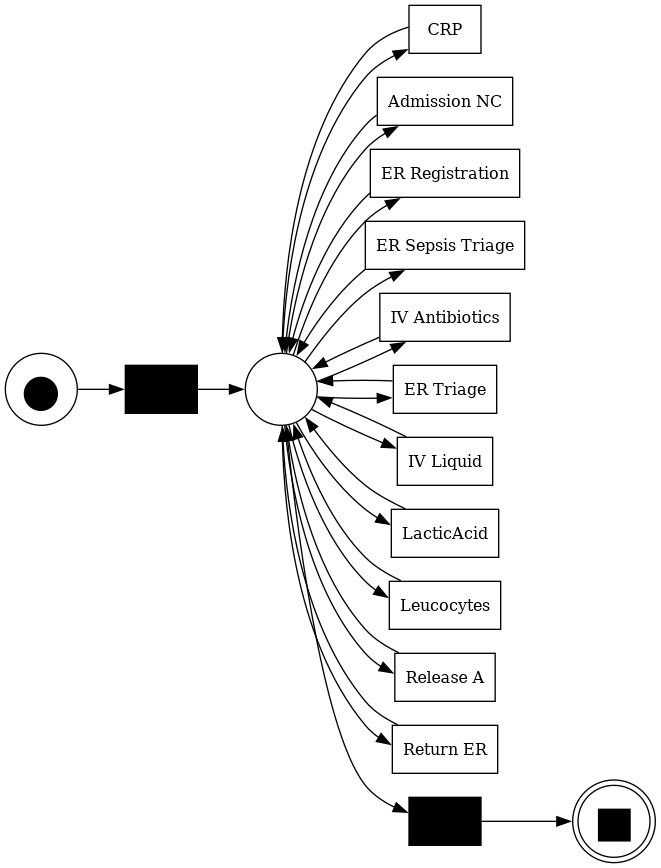

In [ ]:
def build_flower(activities):
    net = PetriNet("flower")
    p_src, p_loop, p_snk = (PetriNet.Place(n) for n in ("source", "loop", "sink"))
    for p in (p_src, p_loop, p_snk): net.places.add(p)

    t_in  = PetriNet.Transition("t_in", None)    # invisible
    t_out = PetriNet.Transition("t_out", None)   # invisible
    net.transitions.add(t_in); net.transitions.add(t_out)
    petri_utils.add_arc_from_to(p_src, t_in, net);  petri_utils.add_arc_from_to(t_in, p_loop, net)
    petri_utils.add_arc_from_to(p_loop, t_out, net); petri_utils.add_arc_from_to(t_out, p_snk, net)

    for i, a in enumerate(activities):
        t = PetriNet.Transition(f"t_{i}", a)
        net.transitions.add(t)
        petri_utils.add_arc_from_to(p_loop, t, net)
        petri_utils.add_arc_from_to(t, p_loop, net)

    return net, Marking({p_src: 1}), Marking({p_snk: 1})

net_flower, im_flower, fm_flower = build_flower(activities)
pm4py.view_petri_net(net_flower, im_flower, fm_flower)

**4b. High-precision net: the variant (trace) model.** An exclusive choice among one sequential branch per variant in the log.

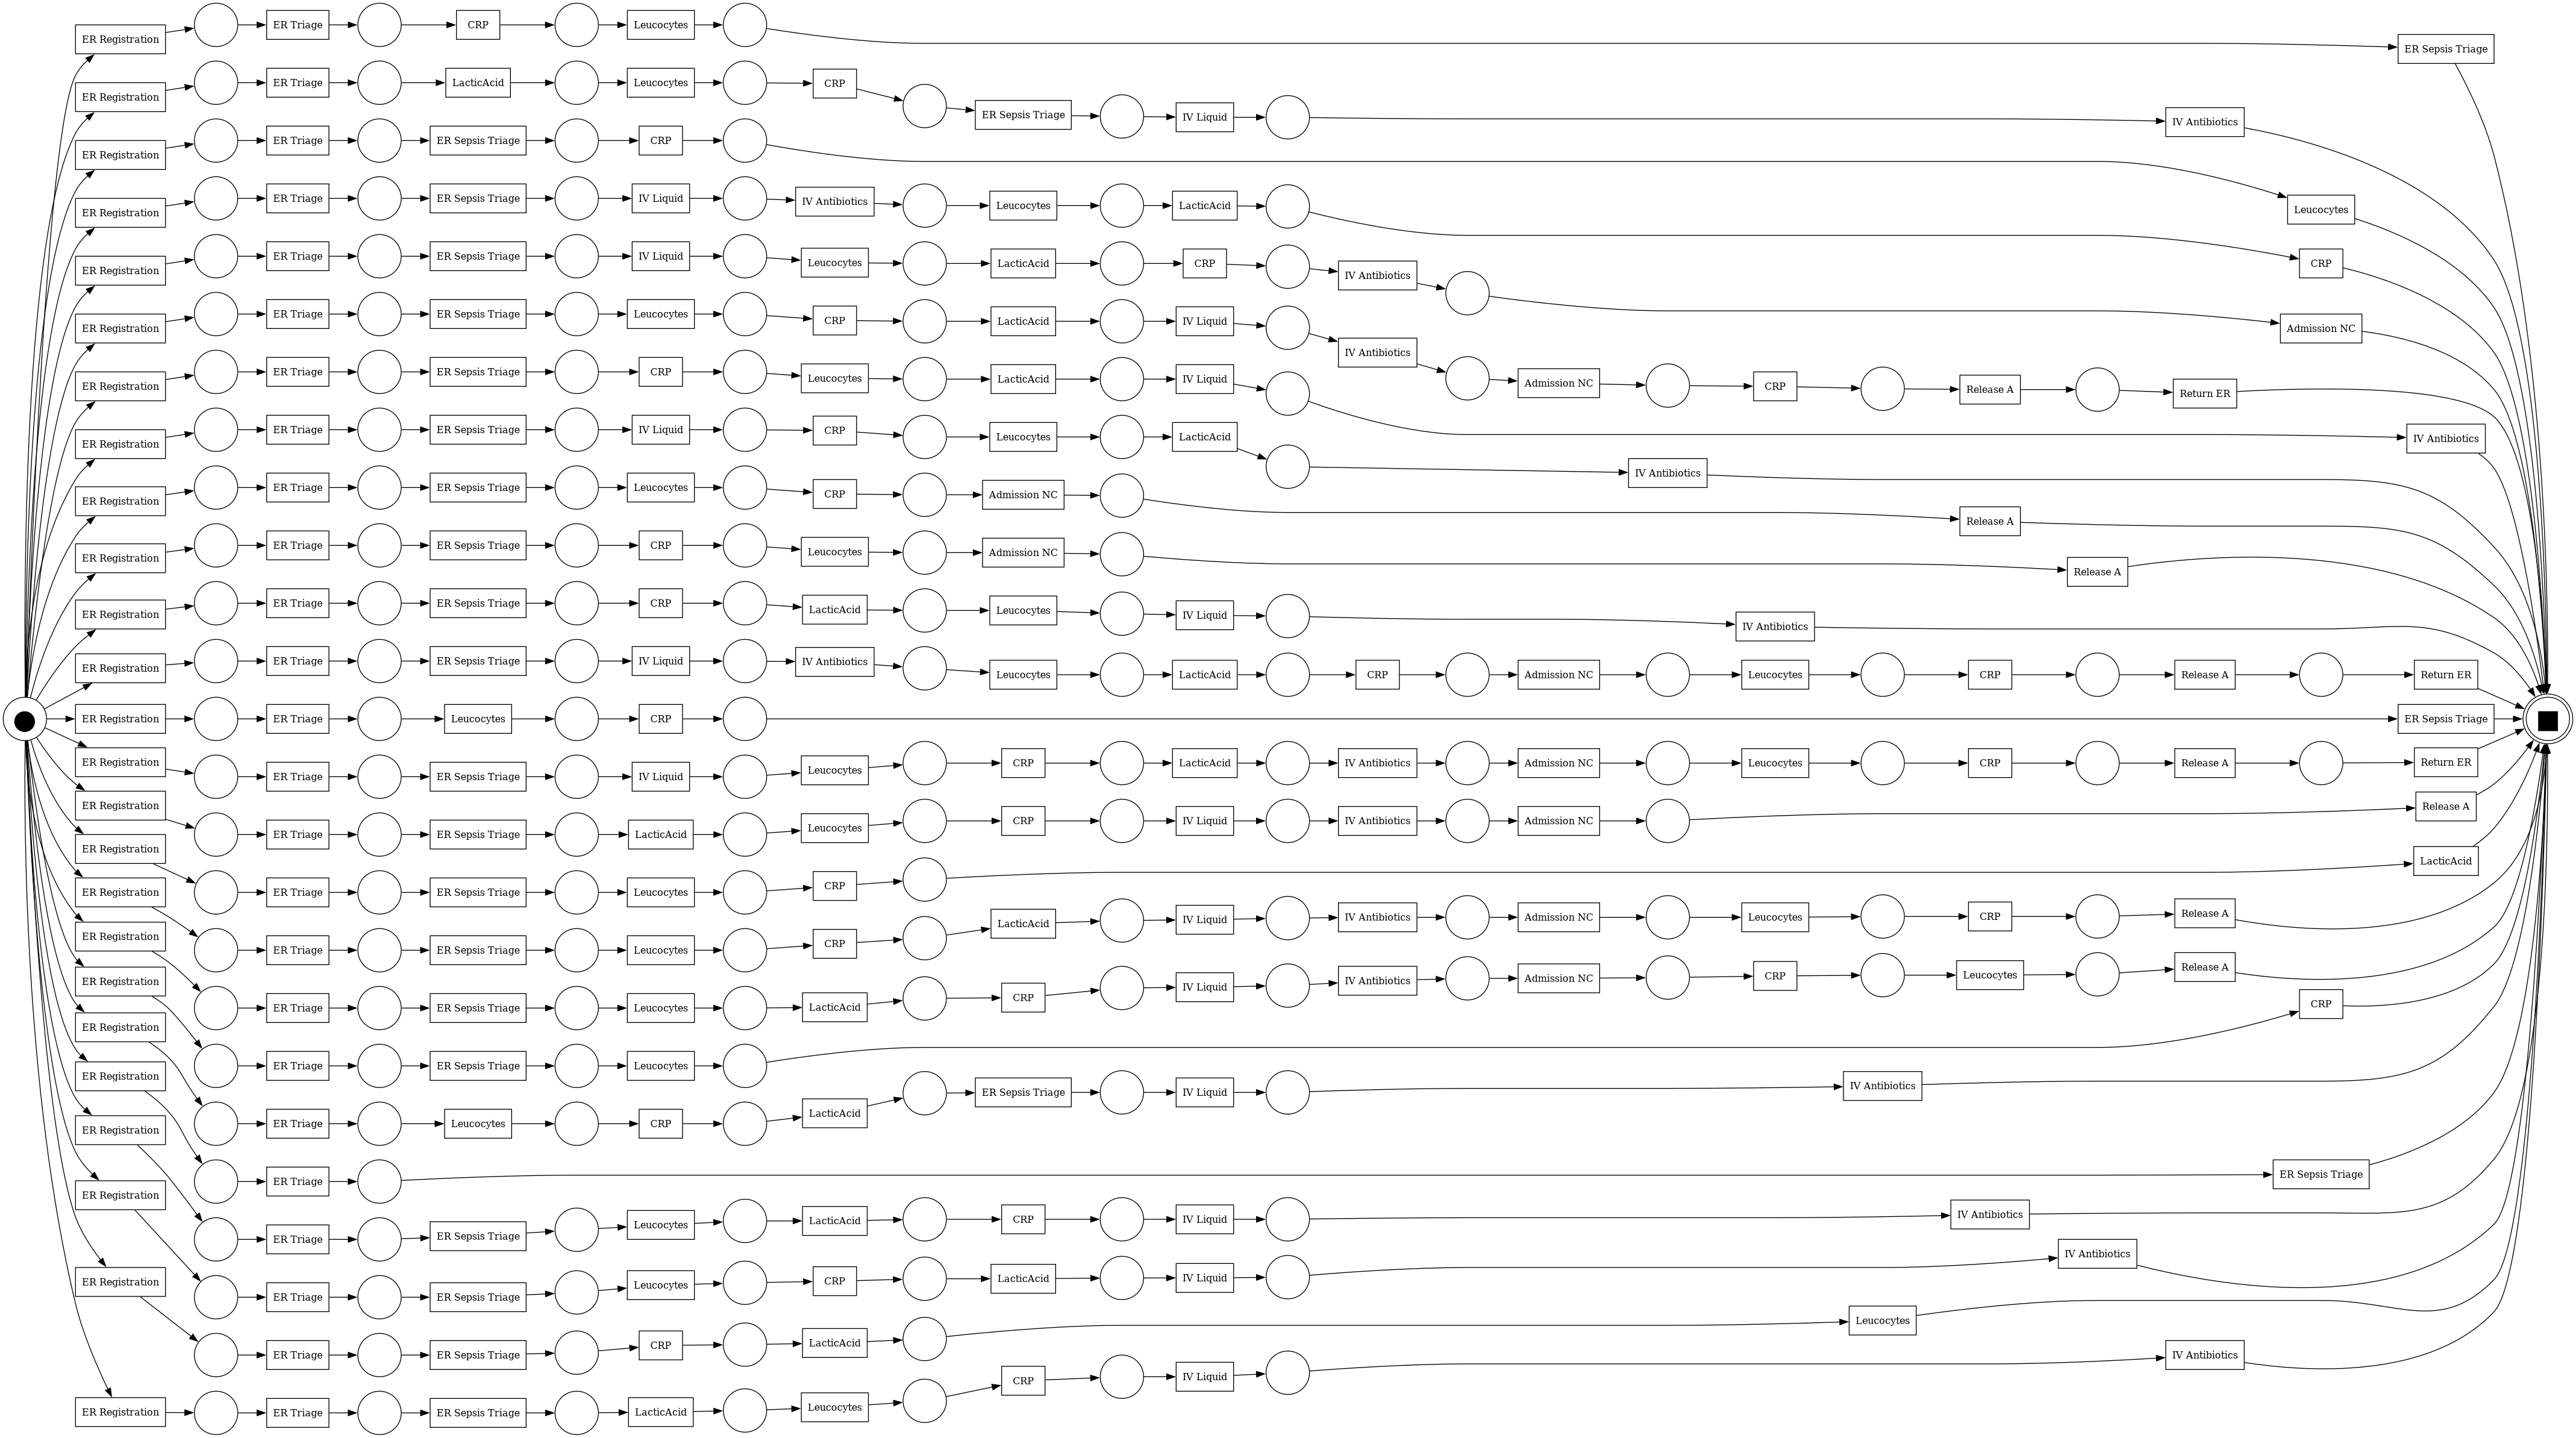

In [ ]:
def build_variant_model(variants):
    net = PetriNet("variant_model")
    p_src, p_snk = PetriNet.Place("source"), PetriNet.Place("sink")
    net.places.add(p_src); net.places.add(p_snk)

    for vi, variant in enumerate(variants):
        prev = p_src
        for ai, act in enumerate(variant):
            t = PetriNet.Transition(f"v{vi}_t{ai}", act)
            net.transitions.add(t)
            petri_utils.add_arc_from_to(prev, t, net)
            if ai == len(variant) - 1:
                petri_utils.add_arc_from_to(t, p_snk, net)
            else:
                p = PetriNet.Place(f"v{vi}_p{ai}")
                net.places.add(p)
                petri_utils.add_arc_from_to(t, p, net)
                prev = p
    return net, Marking({p_src: 1}), Marking({p_snk: 1})

net_var, im_var, fm_var = build_variant_model(list(variants.keys()))
pm4py.view_petri_net(net_var, im_var, fm_var)

In [ ]:
ref_models = {"Flower (high fitness)": (net_flower, im_flower, fm_flower),
              "Variant model (high precision)": (net_var, im_var, fm_var)}

rows = []
for name, (n, i, f) in ref_models.items():
    rows.append({"model": name, "sound": soundness(n, i, f), **evaluate_model(log, n, i, f)})
ref_df = pd.DataFrame(rows).set_index("model")
ref_df

/tmp/ipykernel_20939/3726291515.py:12: DeprecatedWarning: check_soundness is deprecated as of 2.3.0 and will be removed in 3.0.0. this method will be removed in a future release.
  return bool(pm4py.check_soundness(net, im, fm)[0])



aligning log, completed variants ::   0%|          | 0/25 [00:00<?, ?it/s]


aligning log, completed variants :: 100%|██████████| 25/25 [00:00<00:00, 460.81it/s]


computing precision with alignments, completed variants ::   0%|          | 0/70 [00:00<?, ?it/s]


computing precision with alignments, completed variants ::  24%|██▍       | 17/70 [00:00<00:00, 158.65it/s]


computing precision with alignments, completed variants :: 100%|██████████| 70/70 [00:00<00:00, 474.61it/s]

... (17 outputs left out)


computing precision with alignments, completed variants :: 100%|██████████| 70/70 [00:01<00:00, 63.71it/s]


replaying log with TBR, completed traces ::   0%|          | 0/25 [00:00<?, ?it/s]


replaying log with TBR, completed traces :: 100%|██████████| 25/25 [00:00<00:00, 750.68it/s]

,sound,fitness,precision,generalization,simplicity
model,,,,,
Flower (high fitness),True,1.0,0.1797,0.8815,0.4444
Variant model (high precision),True,1.0,1.0000,0.0647,0.8923


**Comments (reference nets)**
- Both nets are **sound** and have **fitness = 1**.
- The *flower model* allows any activity in any order, so **precision is very low (about 0.18)**. Generalization is high (about 0.88) and the net is small, but it says almost nothing about the process.
- The *variant model* has **precision = 1**, because it only allows what is in the log, but **generalization is very low (about 0.07)**: it overfits and any unseen trace is rejected. Note that its simplicity score (about 0.89) is high even though the net is large. The pm4py metric is based on arc degree, and a chain of sequential branches has low degree, so simplicity does not capture size here.

## 5. Inductive Miner with different `noise_threshold` values

In [ ]:
# Install the CBC solver required by PM4Py's soundness checks
!apt-get -qq install coinor-cbc > /dev/null 2>&1

NOISES = [0, 0.2, 0.7, 1]
im_models, rows = {}, []

for nz in NOISES:
    n, i, f = pm4py.discover_petri_net_inductive(log, noise_threshold=nz)
    im_models[nz] = (n, i, f)
    rows.append({"noise_threshold": nz, "sound": soundness(n, i, f),
                 "places": len(n.places), "transitions": len(n.transitions), "arcs": len(n.arcs),
                 **evaluate_model(log, n, i, f)})

im_df = pd.DataFrame(rows).set_index("noise_threshold")
im_df

/tmp/ipykernel_20939/3726291515.py:12: DeprecatedWarning: check_soundness is deprecated as of 2.3.0 and will be removed in 3.0.0. this method will be removed in a future release.
  return bool(pm4py.check_soundness(net, im, fm)[0])



aligning log, completed variants ::   0%|          | 0/25 [00:00<?, ?it/s]


aligning log, completed variants :: 100%|██████████| 25/25 [00:00<00:00, 292.15it/s]


computing precision with alignments, completed variants ::   0%|          | 0/70 [00:00<?, ?it/s]


computing precision with alignments, completed variants ::  79%|███████▊  | 55/70 [00:00<00:00, 536.43it/s]


computing precision with alignments, completed variants :: 100%|██████████| 70/70 [00:00<00:00, 508.60it/s]

... (21 outputs left out)


computing precision with alignments, completed variants :: 100%|██████████| 70/70 [00:00<00:00, 2031.14it/s]


replaying log with TBR, completed traces ::   0%|          | 0/25 [00:00<?, ?it/s]


replaying log with TBR, completed traces :: 100%|██████████| 25/25 [00:00<00:00, 2094.76it/s]

,sound,places,transitions,arcs,fitness,precision,generalization,simplicity
noise_threshold,,,,,,,,
0.0,True,23,25,62,1.0000,0.4649,0.8640,0.6316
0.2,True,20,21,52,0.9324,0.4948,0.8668,0.6508
0.7,True,15,16,36,0.7488,0.7102,0.8004,0.7561
1.0,True,10,14,28,0.5421,0.7285,0.6314,0.7500


=== Inductive Miner, noise_threshold = 0


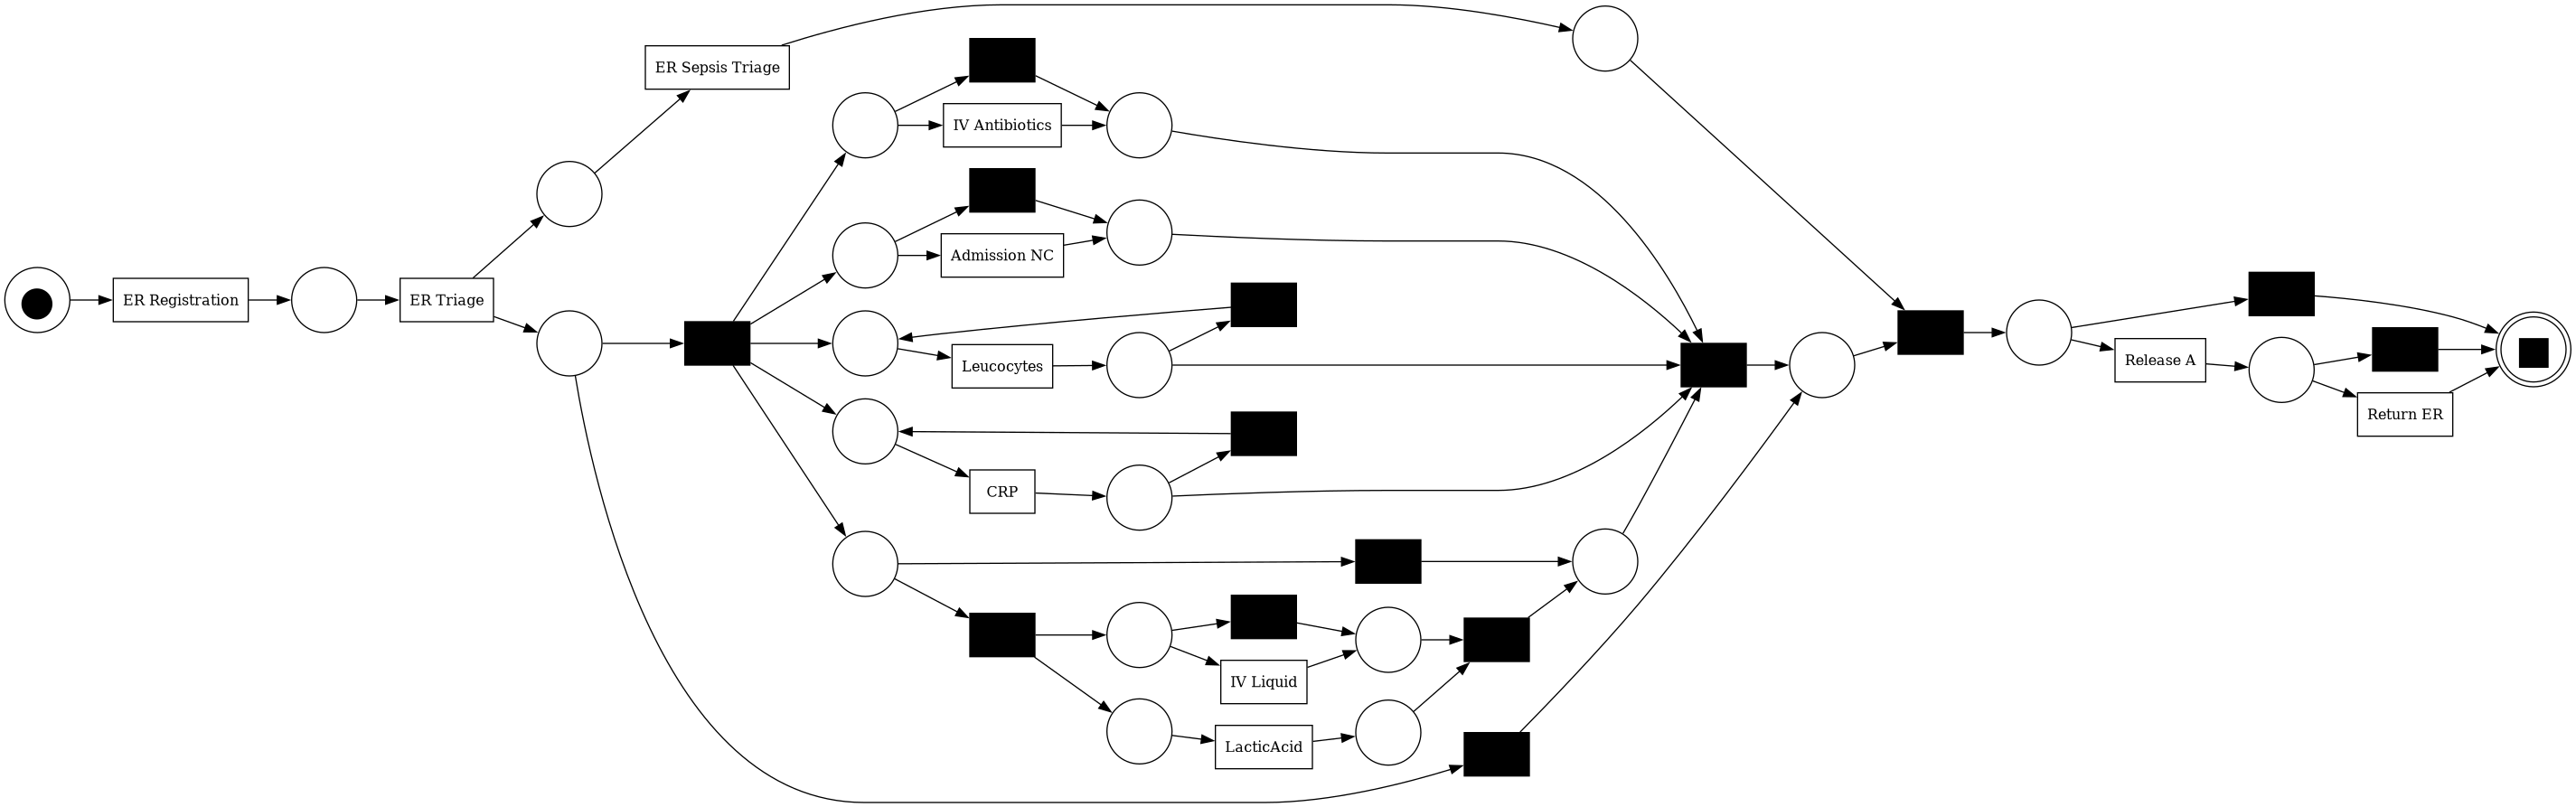

=== Inductive Miner, noise_threshold = 0.2


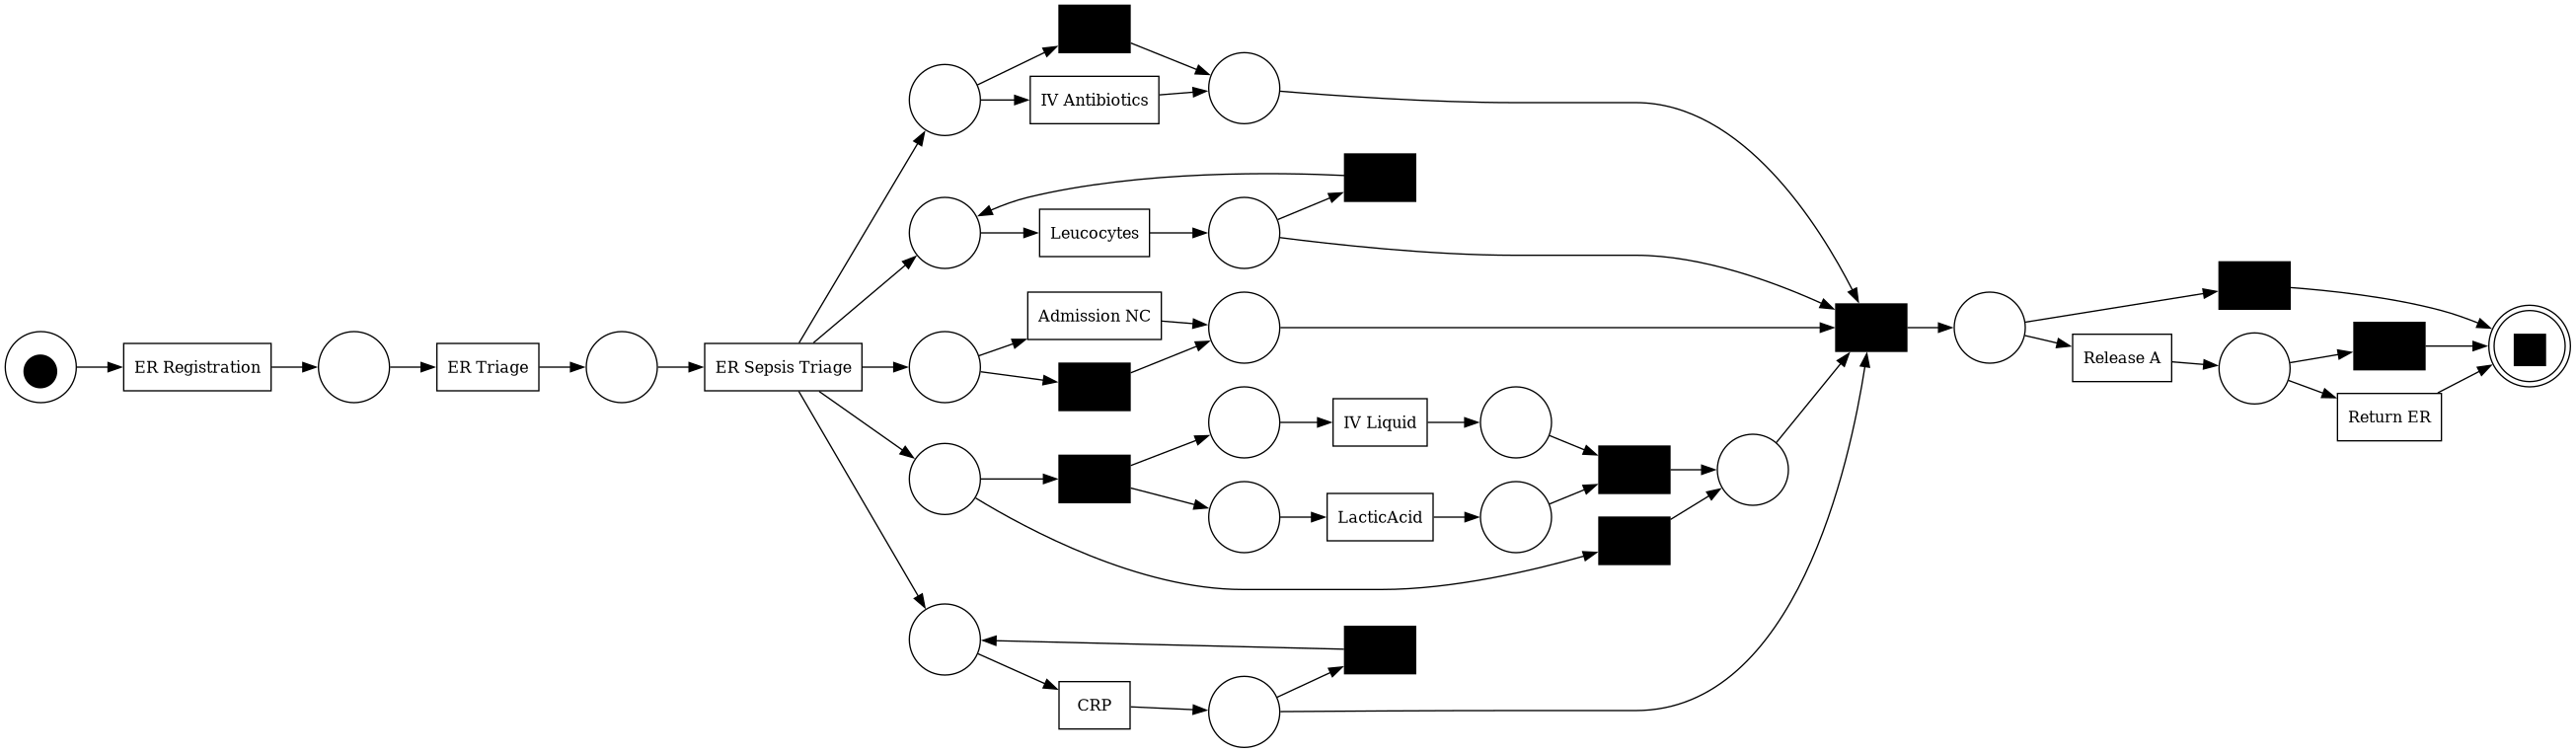

=== Inductive Miner, noise_threshold = 0.7


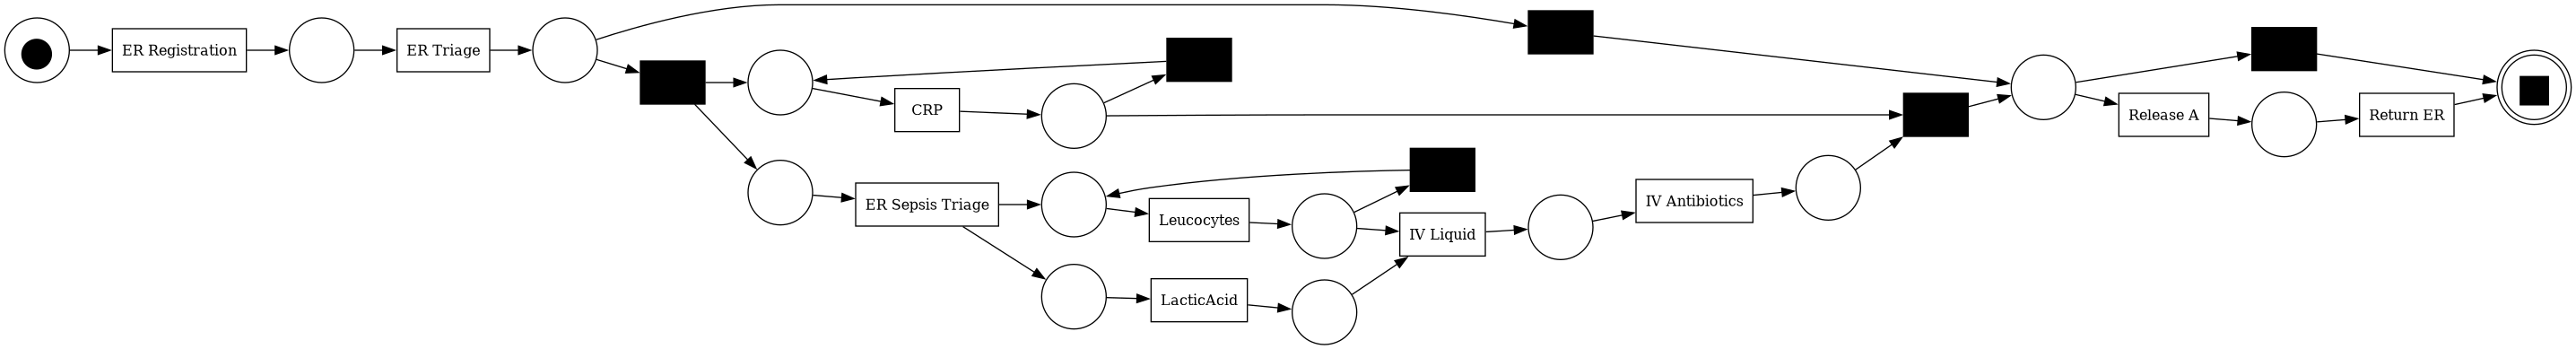

=== Inductive Miner, noise_threshold = 1


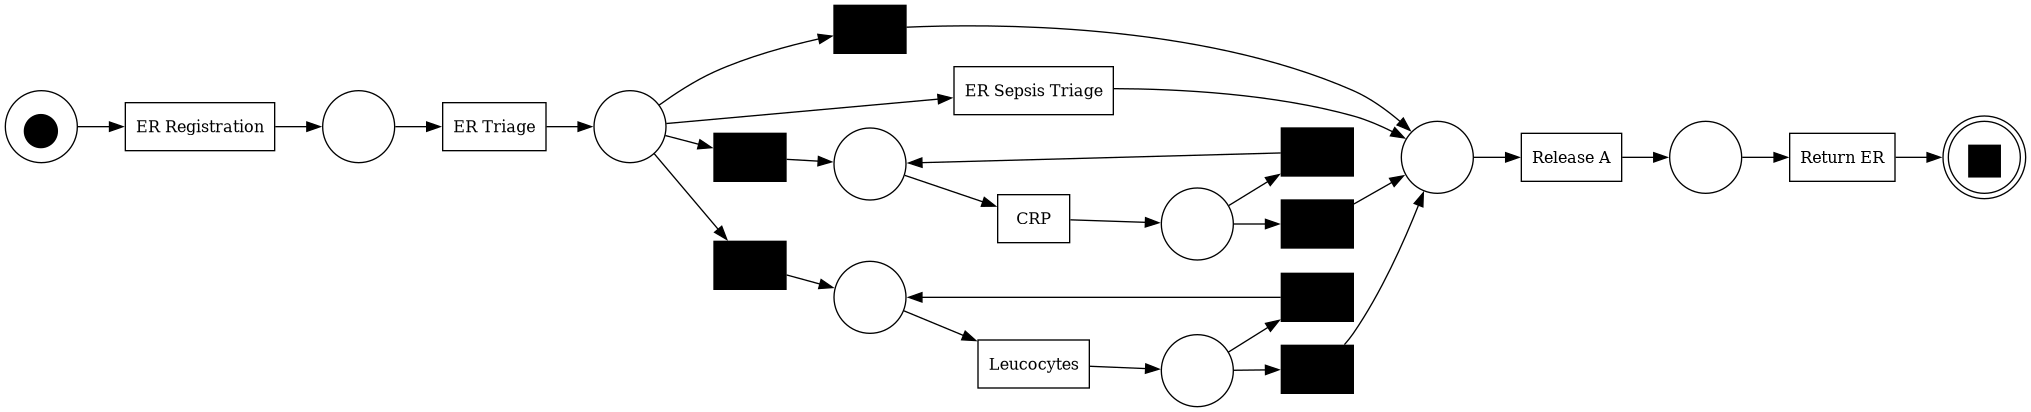

In [ ]:
for nz, (n, i, f) in im_models.items():
    print("=== Inductive Miner, noise_threshold =", nz)
    pm4py.view_petri_net(n, i, f)

In [ ]:
# All 6 models in a single table
all_df = pd.concat([ref_df, im_df.rename(index=lambda x: f"Inductive Miner (noise={x})").drop(columns=["places","transitions","arcs"])])
all_df

,sound,fitness,precision,generalization,simplicity
Flower (high fitness),True,1.0000,0.1797,0.8815,0.4444
Variant model (high precision),True,1.0000,1.0000,0.0647,0.8923
Inductive Miner (noise=0.0),True,1.0000,0.4649,0.8640,0.6316
Inductive Miner (noise=0.2),True,0.9324,0.4948,0.8668,0.6508
Inductive Miner (noise=0.7),True,0.7488,0.7102,0.8004,0.7561
Inductive Miner (noise=1.0),True,0.5421,0.7285,0.6314,0.7500


**Comments (Inductive Miner)**
- **Soundness**: all four nets are sound. The Inductive Miner builds block-structured nets (sequence, choice, parallel, loop), which are sound by construction.
- **Fitness** drops as the threshold grows (about 1.00, 0.93, 0.75, 0.54), because more infrequent behaviour is filtered out and the traces that contain it no longer fit.
- **Precision** rises (about 0.46, 0.49, 0.71, 0.73): the model becomes more restrictive, but not because it is more accurate. It simply drops variants.
- **Generalization** is stable for noise 0 and 0.2 (about 0.86) and falls for 0.7 and 1 (about 0.80 and 0.63).
- **Simplicity** grows from about 0.63 to about 0.75, since the nets have fewer places, transitions and arcs.
- Overall: `noise = 0` is the best fitting model, `0.2` is a good compromise, and `1` is simple but misrepresents the log. Values are for this log with K = 25 variants, so they can differ if you change K.

## 6. Alignments of the least frequent variant against the 4 inductive models

In [ ]:
# least frequent variant (ties: the first one found)
min_count = min(var_counts.values())
rare_variant = [v for v, c in var_counts.items() if c == min_count][0]
print("Least frequent variant (%d traces):" % min_count)
print(" -> ".join(rare_variant))

rare_trace = [t for t in log if tuple(e["concept:name"] for e in t) == tuple(rare_variant)][0]
rare_log = EventLog([deepcopy(rare_trace)])

Least frequent variant (3 traces):
ER Registration -> ER Triage -> ER Sepsis Triage -> IV Liquid -> IV Antibiotics -> Leucocytes -> LacticAcid -> CRP


In [ ]:
def anomalies(alignment):
    out = {"log-only (>> in model)": [], "model-only (>> in log)": []}
    for log_move, model_move in alignment["alignment"]:
        if log_move != ">>" and model_move == ">>":
            out["log-only (>> in model)"].append(log_move)
        elif log_move == ">>" and model_move not in (">>", None):
            out["model-only (>> in log)"].append(model_move)
    return out

rows = []
for nz, (n, i, f) in im_models.items():
    al = pm4py.conformance_diagnostics_alignments(rare_log, n, i, f)[0]
    an = anomalies(al)
    rows.append({"noise_threshold": nz, "alignment cost": al["cost"], "fitness": round(al["fitness"], 4),
                 "log-only moves": an["log-only (>> in model)"],
                 "model-only moves": an["model-only (>> in log)"]})
align_df = pd.DataFrame(rows).set_index("noise_threshold")
align_df

,alignment cost,fitness,log-only moves,model-only moves
noise_threshold,,,,
0.0,7,1.0000,[],[]
0.2,5,1.0000,[],[]
0.7,40003,0.6000,"[Leucocytes, LacticAcid]","[Leucocytes, LacticAcid]"
1.0,70000,0.4167,"[IV Liquid, IV Antibiotics, Leucocytes, LacticAcid, CRP]","[Release A, Return ER]"


In [ ]:
# Full alignment for each model (log move | model move); ">>" means "no move"
for nz, (n, i, f) in im_models.items():
    al = pm4py.conformance_diagnostics_alignments(rare_log, n, i, f)[0]
    print("=== noise_threshold =", nz, "| cost =", al["cost"], "| fitness = %.3f" % al["fitness"])
    for log_move, model_move in al["alignment"]:
        if (log_move, model_move) == (">>", None):
            continue
        tag = "sync" if log_move == model_move else ("log-only" if model_move == ">>" else "model-only" if log_move == ">>" else "mismatch")
        print(f"  {str(log_move):22} | {str(model_move):22} | {tag}")
    print()

=== noise_threshold = 0 | cost = 7 | fitness = 1.000
  ER Registration        | ER Registration        | sync
  ER Triage              | ER Triage              | sync
  ER Sepsis Triage       | ER Sepsis Triage       | sync
  IV Liquid              | IV Liquid              | sync
  IV Antibiotics         | IV Antibiotics         | sync
  Leucocytes             | Leucocytes             | sync
  LacticAcid             | LacticAcid             | sync
  CRP                    | CRP                    | sync

=== noise_threshold = 0.2 | cost = 5 | fitness = 1.000
  ER Registration        | ER Registration        | sync
  ER Triage              | ER Triage              | sync
  ER Sepsis Triage       | ER Sepsis Triage       | sync
  IV Liquid              | IV Liquid              | sync
  IV Antibiotics         | IV Antibiotics         | sync
  Leucocytes             | Leucocytes             | sync
  LacticAcid             | LacticAcid             | sync
  CRP                    | CRP      

**Comments**
- In pm4py's default cost function a visible deviation costs 10000 and an invisible (tau) move costs 1. A cost below 10000 (7 and 5 here) therefore means **no real anomaly**, only silent routing steps.
- `noise = 0` and `0.2`: the rare variant is perfectly replayed (fitness 1.0, no log-only or model-only moves).
- `noise = 0.7`: the model forces `LacticAcid` and `Leucocytes` before the IV treatment, so the alignment has two model-only and two log-only moves (cost 40003, fitness 0.60). This is an **ordering anomaly**.
- `noise = 1`: the model is so reduced that five events of the trace (`IV Liquid`, `IV Antibiotics`, `Leucocytes`, `LacticAcid`, `CRP`) cannot be replayed, and it requires `Release A` / `Return ER`, which the patient never did (cost 70000, fitness 0.42).
- Conclusion: as the noise threshold increases, the anomalies move from none to ordering problems to missing activities, because the rare variant is treated as noise. An anomaly here does not mean the patient was treated incorrectly, it means the model is too coarse.